# Fase 2 — Preprocesamiento, Ingeniería de Variables y Modelo Base

| | |
|---|---|
| **Universidad** | Universidad de La Salle |
| **Facultad** | Facultad de Ingeniería |
| **Asignatura** | Ciencia de Datos — Maestría en Inteligencia Artificial |
| **Docente** | Fabián Camilo Castro Riveros |
| **Autores** | Tony Yu<br>Luis Rodríguez<br>Maydda Rodríguez |
| **Fase** | Fase 2 (25%) |
| **Fecha de entrega** | Domingo 15 de noviembre de 2026 |

**Informe asociado:** *Entregable2_Informe_APA.docx* (normas APA, 7.ª edición). El cuaderno y el informe usan las mismas cifras: el cuaderno las exporta a `modelos/resultados_fase2.json`.

## Resumen

Este cuaderno prepara el conjunto *Metro Interstate Traffic Volume* (Hogue, 2019) para modelar y fija el umbral mínimo de rendimiento. Se eliminaron 17 filas duplicadas y se conservó una fila por hora (7.612 filas repetidas), con lo que quedaron 40.575 horas. Se marcaron como faltantes 11 valores físicamente imposibles y su mecanismo de falta se analizó antes de imputarlos (MAR para la temperatura, con apoyo de una prueba exacta de Fisher; MCAR asumido para el único registro de lluvia). Se crearon cuatro variables de calendario, se dividió el conjunto en 70/15/15 de forma estratificada por nivel de tráfico (razón entre clases de 1,36, sin remuestreo) y la imputación, la codificación y el escalamiento se ajustaron solo con entrenamiento, lo que verifica una auditoría automática de fuga de datos. La referencia trivial da un *R*² de 0,000 y un F1 macro de 0,180; el modelo base lineal alcanza en validación un *R*² de 0,838 (RMSE de 800 vehículos por hora) y un F1 macro de 0,891 (exactitud de 0,888), sin sobreajuste (en entrenamiento, 0,846 y 0,902). Las verificaciones de robustez indican que imputar o eliminar las filas con valores imposibles no cambia los resultados, que una validación temporal (*R*² de 0,847) no empeora el desempeño, que ponderar las clases no aporta y que, sin las variables de calendario, el *R*² cae a 0,037.

*Palabras clave:* preprocesamiento, valores faltantes, fuga de datos, ingeniería de variables, modelo base.

## Estructura del repositorio y reproducibilidad

```
repositorio/
├── data/raw/                  ← Metro_Interstate_Traffic_Volume.csv (entrada de este cuaderno)
├── data/processed/            ← train.csv, val.csv, test.csv (salida de este cuaderno)
├── models/                    ← preprocesador, baselines y resultados_fase2.json (salida)
├── notebooks/                 ← 01_eda · 02_preprocesamiento (este cuaderno) · 03_modelado
├── src/                       ← módulos reutilizables (reproducen esta fase con preparar())
├── dashboard/                 ← aplicación Streamlit (Fase 4)
└── requirements.txt           ← versiones exactas del entorno
```

**Cómo ejecutarlo:** crear un entorno virtual limpio, instalar `requirements.txt` y ejecutar *Kernel → Restart & Run All* desde la carpeta `notebooks/`. El cuaderno registra las versiones usadas en `docs/entorno_fase_2.txt`. La semilla global es 42 y el cuaderno no usa el conjunto de prueba.

## 1. Carga de datos

Se usa el dataset Metro Interstate Traffic Volume (UCI), con el volumen de tráfico por hora en la autopista I-94 en sentido oeste. El archivo se lee desde `data/raw/`; si no existe, se descarga de UCI. La temperatura se convierte de Kelvin a °C, en `holiday` el texto `None` significa "no festivo" y `nivel_trafico` se define con umbrales fijos: bajo (< 1.500), medio (1.500 a 4.499) y alto (≥ 4.500).

Los umbrales se fijan **a priori y como constantes**: no se recalculan con cuantiles de cada conjunto, de modo que la etiqueta tiene la misma definición en entrenamiento, validación y prueba. Se eligieron observando la distribución de `traffic_volume` en el EDA del Entregable 1 (sección 4.3), donde separan las horas de madrugada de bajo flujo, el flujo intermedio y los periodos pico, y dejan las tres clases con proporciones parecidas (sección 4), sin desbalance severo.

In [1]:
# ======================================================================
# Fase 2 · Preprocesamiento, ingeniería de variables y modelo base
# Entorno: ver la celda de versiones. Semilla global: 42.
# ======================================================================
import gzip
import io
import json
import sys
import urllib.request
import zipfile
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy.stats import fisher_exact
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
    mean_absolute_error, mean_squared_error, precision_score, r2_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
SEMILLA = 42
np.random.seed(SEMILLA)

# --- Formato numérico español (1.234,567) para tablas y ejes ---
def es(x, dec=3):
    return f"{x:,.{dec}f}".replace(",", "_").replace(".", ",").replace("_", ".")

pd.set_option("display.float_format", es)

def ejes_es(fig):
    """Aplica el formato español a los ejes numéricos de una figura."""
    def fmt(v, _):
        txt = es(v, 2)
        return txt.rstrip("0").rstrip(",") if "," in txt else txt
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if isinstance(eje.get_major_formatter(), ScalarFormatter):
                eje.set_major_formatter(FuncFormatter(fmt))

# --- Datos de origen (UCI). Se leen de fase_1/data; si no existen, se descargan ---
URL = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
RUTA = Path("../data/raw/Metro_Interstate_Traffic_Volume.csv")

if not RUTA.exists():
    RUTA.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(URL) as resp:
        zf = zipfile.ZipFile(io.BytesIO(resp.read()))
    RUTA.write_bytes(gzip.decompress(zf.read("Metro_Interstate_Traffic_Volume.csv.gz")))

# keep_default_na=False: el texto 'None' de 'holiday' es una categoría válida (no festivo), no un faltante
df = pd.read_csv(RUTA, keep_default_na=False, na_values=[""], parse_dates=["date_time"])
df["temp"] = df["temp"] - 273.15      # Kelvin → °C

# Variable objetivo categórica: umbrales fijos y constantes (iguales en train, val y test)
UMBRAL_BAJO, UMBRAL_ALTO = 1500, 4500
df["nivel_trafico"] = pd.cut(
    df["traffic_volume"], bins=[-1, UMBRAL_BAJO - 1, UMBRAL_ALTO - 1, np.inf], labels=["bajo", "medio", "alto"]
)
print(df.shape)
df.head()

(48204, 10)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,nivel_trafico
0,None,"15,130","0,000","0,000",40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,alto
1,None,"16,210","0,000","0,000",75,Clouds,broken clouds,2012-10-02 10:00:00,4516,alto
2,None,"16,430","0,000","0,000",90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,alto
3,None,"16,980","0,000","0,000",90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,alto
4,None,"17,990","0,000","0,000",75,Clouds,broken clouds,2012-10-02 13:00:00,4918,alto


### Entorno y versiones

Se registran las versiones de las librerías usadas y se guarda `requirements.txt`, para que el cuaderno se pueda reproducir con el mismo entorno.

In [2]:
# Versiones exactas del entorno en que se ejecuta el cuaderno.
# El archivo requirements.txt resultante es el que se versiona en el repositorio.
paquetes = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "ipykernel"]
versiones = {p: version(p) for p in paquetes}
print("Python", sys.version.split()[0])
print(versiones)
_ = Path("../docs/entorno_fase_2.txt").write_text("\n".join(f"{p}=={v}" for p, v in versiones.items()) + "\n")

Python 3.13.18
{'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'ipykernel': '7.4.0'}


## 2. Limpieza de datos

### Duplicados

Hay filas idénticas y horas repetidas. La fuente agrega una fila por cada condición climática reportada en la hora. En esas horas repetidas el volumen de tráfico es siempre el mismo; lo que cambia es sobre todo la categoría del clima y, en pocas horas, la temperatura, la nubosidad o la lluvia. Se eliminan las filas idénticas y se conserva una fila por hora (la primera), para que cada hora cuente una sola vez y no pese más en los modelos. Así, en esas horas se conserva solo la primera condición climática reportada.

In [3]:
# --- Duplicados: filas idénticas y horas repetidas ---
n_inicial = len(df)
identicas = int(df.duplicated().sum())
df = df.drop_duplicates()                      # 1) filas idénticas en todas las columnas

# 2) horas repetidas con contenido distinto: ¿qué columnas cambian dentro de una misma hora?
por_hora = df.groupby("date_time")
distinto = {col: int((por_hora[col].nunique() > 1).sum())
            for col in ["traffic_volume", "weather_main", "temp", "clouds_all", "rain_1h"]}
horas_repetidas = int(df["date_time"].duplicated().sum())
df = df.drop_duplicates(subset="date_time", keep="first").reset_index(drop=True)   # una fila por hora

resumen_limpieza = pd.DataFrame({
    "valor": [n_inicial, identicas, horas_repetidas] + list(distinto.values()) + [len(df)]
}, index=["Filas iniciales", "Filas idénticas eliminadas", "Horas repetidas eliminadas"]
  + [f"Horas repetidas con {col} distinto" for col in distinto] + ["Filas finales"])
resumen_limpieza

,valor
Filas iniciales,48204
Filas idénticas eliminadas,17
Horas repetidas eliminadas,7612
Horas repetidas con traffic_volume distinto,0
Horas repetidas con weather_main distinto,5349
Horas repetidas con temp distinto,78
Horas repetidas con clouds_all distinto,32
Horas repetidas con rain_1h distinto,9
Filas finales,40575


### Inconsistencias en categorías

`weather_description` escribe la misma categoría con mayúsculas distintas (por ejemplo, "sky is clear" y "Sky is Clear"). Se pasa todo a minúsculas.

In [4]:
# Se unifican mayúsculas/minúsculas en la descripción del clima
antes = df["weather_description"].nunique()
df["weather_description"] = df["weather_description"].str.lower()
despues = df["weather_description"].nunique()
print(f"Categorías de weather_description: {antes} antes, {despues} después")

Categorías de weather_description: 35 antes, 34 después


### Valores imposibles y mecanismo de falta

El archivo no tiene celdas vacías, pero sí valores físicamente imposibles: `temp` = −273,15 °C (0 K) y `rain_1h` = 9.831,3 mm en una hora. Son errores de medición, así que se marcan como faltantes (`NaN`). Antes de decidir cómo tratarlos se revisa cuándo ocurren, para identificar el mecanismo de falta:

- **MCAR** (completamente al azar): la falta no depende de ninguna variable.
- **MAR** (al azar): la falta depende de variables observadas, como la fecha o la hora.
- **MNAR** (no al azar): la falta depende del propio valor que no se observó.

In [5]:
# Valores físicamente imposibles → NaN (detectados en el EDA del Entregable 1)
df.loc[df["temp"] == -273.15, "temp"] = np.nan    # 0 K
df.loc[df["rain_1h"] > 100, "rain_1h"] = np.nan   # > 100 mm en una hora

faltantes = df[df["temp"].isna() | df["rain_1h"].isna()]
faltantes[["date_time", "temp", "rain_1h", "clouds_all", "weather_main", "weather_description", "traffic_volume"]]

,date_time,temp,rain_1h,clouds_all,weather_main,weather_description,traffic_volume
10079,2014-01-31 03:00:00,NaN,"0,000",0,Clear,sky is clear,361
10080,2014-01-31 04:00:00,NaN,"0,000",0,Clear,sky is clear,734
10081,2014-01-31 05:00:00,NaN,"0,000",0,Clear,sky is clear,2557
10082,2014-01-31 06:00:00,NaN,"0,000",0,Clear,sky is clear,5150
10127,2014-02-02 03:00:00,NaN,"0,000",0,Clear,sky is clear,291
10128,2014-02-02 04:00:00,NaN,"0,000",0,Clear,sky is clear,284
10129,2014-02-02 05:00:00,NaN,"0,000",0,Clear,sky is clear,434
10130,2014-02-02 06:00:00,NaN,"0,000",0,Clear,sky is clear,739
10131,2014-02-02 07:00:00,NaN,"0,000",0,Clear,sky is clear,962
10132,2014-02-02 08:00:00,NaN,"0,000",0,Clear,sky is clear,1670


In [6]:
# Si la falta de temp fuera MCAR, se repartiría de forma pareja entre los meses
falta_por_mes = pd.DataFrame({
    "% de horas sin temp": df.groupby(df["date_time"].dt.month)["temp"].apply(lambda s: s.isna().mean() * 100),
}).rename_axis("mes").T
falta_por_mes

mes,1,2,3,4,5,6,7,8,9,10,11,12
% de horas sin temp,"0,123","0,193","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,000"


**Contraste formal del mecanismo de falta de `temp`.** Se compara, con la prueba exacta de Fisher (una cola), la proporción de horas sin temperatura dentro de los meses y las horas del día donde ocurre la falta frente al resto. Como esos grupos se definen *después* de ver dónde están las faltas, el valor *p* es orientativo y no confirmatorio. La prueba permite descartar que la falta sea completamente al azar (MCAR), pero no distingue entre MAR y MNAR: esa diferencia depende de los valores no observados y no se puede contrastar con los datos disponibles (Little y Rubin, 2019; Rubin, 1976).

In [7]:
# Prueba exacta de Fisher: ¿la falta de temp se concentra en ciertos meses y horas?
falta = df["temp"].isna()

def prueba_fisher(en_grupo):
    """Tabla 2×2 (falta / no falta) × (dentro / fuera del grupo) y valor p de una cola."""
    tabla = [[int((falta & en_grupo).sum()), int((falta & ~en_grupo).sum())],
             [int((~falta & en_grupo).sum()), int((~falta & ~en_grupo).sum())]]
    return fisher_exact(tabla, alternative="greater")[1], tabla

meses_obs = sorted(int(m) for m in df.loc[falta, "date_time"].dt.month.unique())
horas_obs = sorted(int(h) for h in df.loc[falta, "date_time"].dt.hour.unique())
p_mes, t_mes = prueba_fisher(df["date_time"].dt.month.isin(meses_obs))
p_hora, t_hora = prueba_fisher(df["date_time"].dt.hour.isin(horas_obs))

fisher_tabla = pd.DataFrame({
    "grupo": [f"meses {meses_obs}", f"horas {horas_obs}"],
    "% de las horas del conjunto en el grupo": [(t_mes[0][0] + t_mes[1][0]) / len(df) * 100,
                                                  (t_hora[0][0] + t_hora[1][0]) / len(df) * 100],
    "faltas dentro del grupo": [t_mes[0][0], t_hora[0][0]],
    "faltas totales": [int(falta.sum())] * 2,
    "valor p (Fisher)": [f"{p_mes:.1e}".replace(".", ","), f"{p_hora:.1e}".replace(".", ",")],
}).set_index("grupo")
fisher_tabla

,% de las horas del conjunto en el grupo,faltas dentro del grupo,faltas totales,valor p (Fisher)
grupo,,,,
"meses [1, 2]","15,672",10,10,"8,9e-09"
"horas [3, 4, 5, 6, 7, 8]","24,895",10,10,"9,1e-07"


### Horas ausentes en la serie temporal

Además de los valores imposibles, faltan horas completas en el periodo: no existe la fila, ni siquiera el volumen de tráfico. Se cuenta qué proporción de horas falta en cada año.

In [8]:
# Serie horaria completa esperada vs. horas realmente presentes
todas = pd.date_range(df["date_time"].min(), df["date_time"].max(), freq="h")
ausente = pd.Series(~todas.isin(df["date_time"]), index=todas)
cobertura_anual = pd.DataFrame({
    "horas esperadas": ausente.groupby(ausente.index.year).size(),
    "horas ausentes": ausente.groupby(ausente.index.year).sum(),
    "% ausente": ausente.groupby(ausente.index.year).mean() * 100,
}).rename_axis("año")
cobertura_anual

,horas esperadas,horas ausentes,% ausente
año,,,
2012,2175,72,"3,310"
2013,8760,1466,"16,735"
2014,8760,4259,"48,619"
2015,8760,5167,"58,984"
2016,8784,946,"10,770"
2017,8760,47,"0,537"
2018,6552,19,"0,290"


In [9]:
# Bloques de horas ausentes consecutivas, de mayor a menor duración
bloque = (ausente != ausente.shift()).cumsum()[ausente]
bloques = pd.DataFrame({
    "inicio": bloque.index.to_series().groupby(bloque.to_numpy()).min(),
    "fin": bloque.index.to_series().groupby(bloque.to_numpy()).max(),
    "horas": bloque.groupby(bloque.to_numpy()).size(),
})
bloques["días"] = bloques["horas"] / 24
bloques["duración"] = np.where(bloques["horas"] >= 24, "24 h o más", "menos de 24 h")
resumen_bloques = bloques.groupby("duración").agg(bloques=("horas", "size"), horas=("horas", "sum"))
resumen_bloques["% de horas ausentes"] = resumen_bloques["horas"] / ausente.sum() * 100
display(resumen_bloques)
n_bloques_1h = int((bloques["horas"] == 1).sum())
print(f"Bloques de una sola hora: {n_bloques_1h}")
bloques_top = bloques.sort_values("horas", ascending=False).head(5).drop(columns="duración").reset_index(drop=True)
bloques_top

,bloques,horas,% de horas ausentes
duración,,,
24 h o más,12,8210,"68,554"
menos de 24 h,2576,3766,"31,446"


Bloques de una sola hora: 2192


,inicio,fin,horas,días
0,2014-08-08 02:00:00,2015-06-11 19:00:00,7386,"307,750"
1,2013-10-27 02:00:00,2013-11-06 03:00:00,242,"10,083"
2,2015-06-14 21:00:00,2015-06-19 17:00:00,117,"4,875"
3,2014-04-29 09:00:00,2014-05-04 04:00:00,116,"4,833"
4,2015-10-23 12:00:00,2015-10-27 07:00:00,92,"3,833"


In [10]:
# Horas ausentes en huecos de menos de 24 h, por año
cortas = bloque[bloques.loc[bloque.to_numpy(), "horas"].to_numpy() < 24].index
huecos_cortos = pd.Series(cortas.year).value_counts().sort_index().rename("horas ausentes en huecos cortos").rename_axis("año").to_frame()
huecos_cortos

,horas ausentes en huecos cortos
año,
2012,72
2013,1125
2014,545
2015,1012
2016,946
2017,47
2018,19


**Interpretación**

- Las 10 temperaturas imposibles ocurren solo en enero y febrero, en dos madrugadas de 2014 (31 de enero y 2 de febrero), con cielo despejado. La falta no se reparte al azar entre meses: depende de la fecha y la hora, que son observadas, por lo que se trata como MAR. No se puede descartar del todo que el sensor falle con frío extremo (MNAR); en ese caso la mediana imputada quedaría algo por encima del valor real, con un efecto mínimo al ser solo 10 horas.
- La prueba de Fisher respalda que la falta de `temp` no es completamente al azar (MCAR), pero no separa MAR de MNAR (no es contrastable con los datos observados).
- La lluvia imposible es un único registro, en julio de 2016, con descripción "very heavy rain". No hay un patrón que lo explique; con un solo registro el mecanismo no se puede contrastar estadísticamente, por lo que se asume MCAR y la sección 8.2 comprueba que esa decisión no cambia los resultados.
- Las horas ausentes se concentran en 2014 y 2015, años en los que falta cerca de la mitad y casi el 60% de las horas. Hay dos tipos de faltas:
  - **Bloques de 24 h o más:** son solo 12 pero reúnen más de dos tercios de las horas ausentes; el mayor dura unos 10 meses (agosto de 2014 a junio de 2015). Corresponden a periodos en que el equipo no registró datos: la falta depende de la fecha, que es observada, y como cubren días completos, sin distinguir horas de tráfico alto o bajo, se tratan como MAR.
  - **Huecos de menos de 24 h:** son la gran mayoría de los bloques, casi todos de una sola hora. Se concentran entre 2013 y 2016 y casi desaparecen en 2017 y 2018: la falta depende de la fecha, que es observada, por lo que también se tratan como MAR.

## 3. Ingeniería de variables

Se crean variables derivadas de `date_time` y `holiday`, porque el tráfico sigue la rutina de las personas:

| Variable | Tipo | Justificación |
|---|---|---|
| `hora` | Cualitativa ordinal (0–23) | El tráfico cambia con la hora: sube en la mañana, tiene picos al entrar y salir del trabajo y cae en la madrugada. |
| `dia_semana` | Cualitativa nominal (0 = lunes … 6 = domingo) | Los días laborales tienen más tráfico que los fines de semana. |
| `mes` | Cualitativa ordinal (1–12) | Recoge la estacionalidad: invierno, vacaciones y temporada escolar. |
| `es_festivo` | Binaria (0/1) | En festivos baja el tráfico laboral. La fuente marca el festivo solo en la hora 00:00, por lo que se extiende a todas las horas de ese día. |

`hora`, `dia_semana` y `mes` se tratan como categorías porque su efecto sobre el tráfico no es lineal: la hora 17 no es "más" que la hora 3 en un sentido proporcional. `hora`, `dia_semana` y `mes` se calculan a partir de la fecha de cada fila, y `es_festivo` a partir del calendario de festivos que trae la fuente. Ninguna usa la variable objetivo ni estadísticas calculadas con los datos, por lo que no generan fuga.

In [11]:
# Variables de calendario derivadas de date_time (no usan la variable objetivo → sin fuga)
df["hora"] = df["date_time"].dt.hour
df["dia_semana"] = df["date_time"].dt.day_of_week     # 0 = lunes … 6 = domingo
df["mes"] = df["date_time"].dt.month

# es_festivo: la fuente marca el festivo solo en la hora 00:00; se extiende a todas las horas de ese día
dias_festivos = df.loc[df["holiday"] != "None", "date_time"].dt.normalize().unique()
df["es_festivo"] = df["date_time"].dt.normalize().isin(dias_festivos).astype(int)

print(f"Horas marcadas en holiday: {(df['holiday'] != 'None').sum()}")
print(f"Horas con es_festivo = 1: {df['es_festivo'].sum()}")
festivo_prom = df.groupby("es_festivo")["traffic_volume"].mean().rename("tráfico promedio (vehículos/h)").to_frame()
festivo_prom

Horas marcadas en holiday: 53
Horas con es_festivo = 1: 1203


,tráfico promedio (vehículos/h)
es_festivo,
0,"3.313,014"
1,"2.558,737"


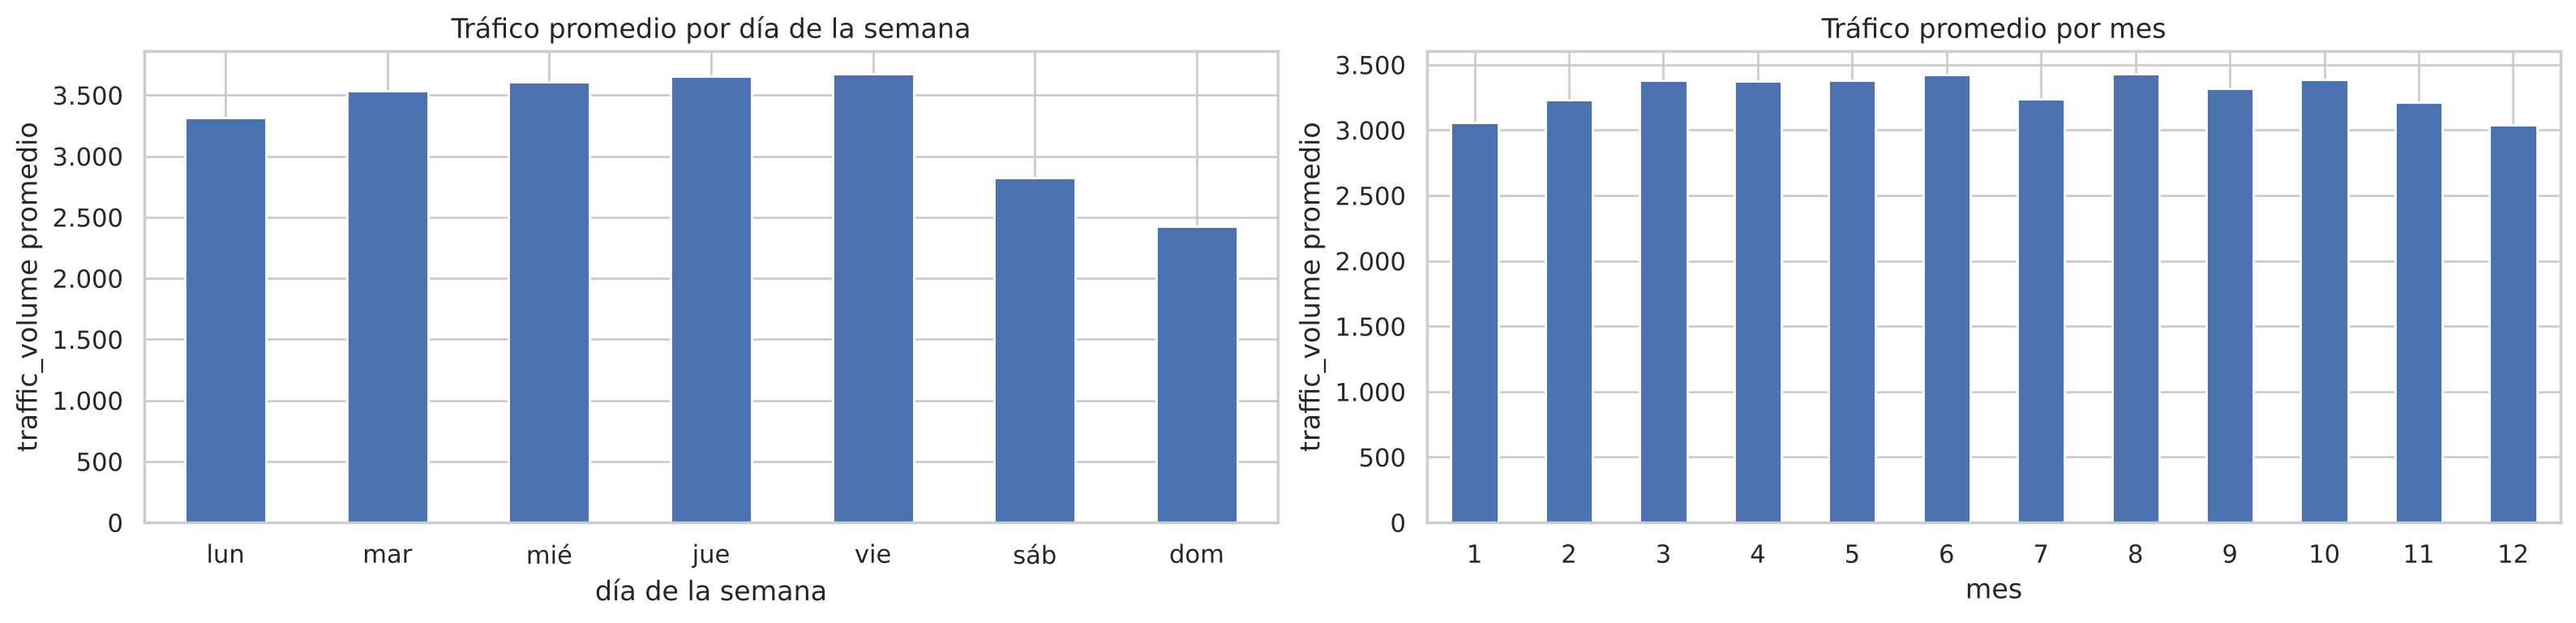

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
nombres = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
df.groupby("dia_semana")["traffic_volume"].mean().set_axis(nombres).plot.bar(
    ax=axes[0], title="Tráfico promedio por día de la semana", xlabel="día de la semana"
)
df.groupby("mes")["traffic_volume"].mean().plot.bar(ax=axes[1], title="Tráfico promedio por mes")
for ax in axes:
    ax.set_ylabel("traffic_volume promedio")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
ejes_es(plt.gcf())
plt.show()

**Interpretación**

- Los días laborales tienen más tráfico que el fin de semana, y el domingo es el día con menos tráfico. Esto respalda usar `dia_semana`.
- El tráfico baja en los meses de invierno (diciembre y enero) y es más alto entre marzo y octubre, con una baja en julio. Esto respalda usar `mes`.
- Al extender el festivo a todo el día, se pasa de 53 horas marcadas a 1.203. Las horas festivas tienen en promedio unos 750 vehículos menos por hora que las no festivas.

### Verificación de la cobertura de festivos

`es_festivo` se construye a partir de las filas donde `holiday` no es `None`. Si el dataset marca el festivo en una sola fila del día y esa hora falta en la serie, ese día quedaría sin marcar. Se comprueba contra el calendario de festivos federales de EE. UU. (el de `pandas`), considerando solo días en que hay datos.

In [13]:
from pandas.tseries.holiday import USFederalHolidayCalendar

dias = df["date_time"].dt.normalize()
horas_por_dia = dias.value_counts()
federales = USFederalHolidayCalendar().holidays(start=dias.min(), end=dias.max())
marcados = set(pd.DatetimeIndex(dias_festivos))

con_datos = [d for d in federales if d in horas_por_dia.index]     # festivos federales con datos ese día
sin_marca = [d for d in con_datos if d not in marcados]            # ...que el dataset no marca
print(f"Festivos federales con datos ese día: {len(con_datos)} | marcados en es_festivo: {len(con_datos) - len(sin_marca)} | sin marcar: {len(sin_marca)}")

tabla_sin_marca = pd.DataFrame({
    "fecha": sin_marca,
    "día": [d.day_name() for d in sin_marca],
    "horas disponibles ese día": [int(horas_por_dia[d]) for d in sin_marca],
    "tráfico medio ese día": [df.loc[dias == d, "traffic_volume"].mean() for d in sin_marca],
}).reset_index(drop=True)
horas_sin_marca = int(sum(horas_por_dia[d] for d in sin_marca))

if sin_marca:
    display(tabla_sin_marca)
    display(Markdown(
        f"**Lectura.** Quedan {len(sin_marca)} festivos federales sin marcar ({horas_sin_marca} horas, "
        f"{es(horas_sin_marca / len(df) * 100, 2)} % de las horas), porque la fila 00:00 que usa la fuente para marcarlos no existe en la serie. "
        "Su tráfico medio es menor que el de un día laboral normal, de modo que lo correcto sería marcarlos. "
        "El efecto sobre los modelos es despreciable por su peso en la muestra, y no se corrige aquí para mantener la misma definición de `es_festivo` que el Entregable 1; "
        "queda como mejora para la Fase 3."))
else:
    display(Markdown("**Lectura.** Todos los festivos federales con datos quedaron marcados en `es_festivo`."))

Festivos federales con datos ese día: 51 | marcados en es_festivo: 48 | sin marcar: 3


,fecha,día,horas disponibles ese día,tráfico medio ese día
0,2013-01-21,Monday,20,"2.645,550"
1,2014-07-04,Friday,20,"2.515,500"
2,2016-01-18,Monday,14,"3.087,071"


**Lectura.** Quedan 3 festivos federales sin marcar (54 horas, 0,13 % de las horas), porque la fila 00:00 que usa la fuente para marcarlos no existe en la serie. Su tráfico medio es menor que el de un día laboral normal, de modo que lo correcto sería marcarlos. El efecto sobre los modelos es despreciable por su peso en la muestra, y no se corrige aquí para mantener la misma definición de `es_festivo` que el Entregable 1; queda como mejora para la Fase 3.

## 4. Partición de datos y desbalance

Se divide en entrenamiento (70%), validación (15%) y prueba (15%), estratificando por `nivel_trafico` para que las tres clases tengan la misma proporción en cada conjunto. Se usa la misma partición para regresión y clasificación. La partición se hace antes de imputar, codificar y escalar, para que esos pasos se ajusten solo con entrenamiento. La partición es aleatoria estratificada, como exige la guía; como los datos son una serie horaria (horas vecinas pueden quedar en conjuntos distintos), la sección 8.2 la complementa con una verificación temporal que usa solo entrenamiento y validación.

In [14]:
train, temp_ = train_test_split(df, test_size=0.30, stratify=df["nivel_trafico"], random_state=SEMILLA)
val, test = train_test_split(temp_, test_size=0.50, stratify=temp_["nivel_trafico"], random_state=SEMILLA)

orden = ["bajo", "medio", "alto"]
particion = pd.DataFrame({
    nombre: d["nivel_trafico"].value_counts(normalize=True).reindex(orden) * 100
    for nombre, d in [("entrenamiento", train), ("validación", val), ("prueba", test)]
}).T
particion.columns = [f"% {c}" for c in orden]
particion.insert(0, "filas", [len(train), len(val), len(test)])
particion.insert(1, "% del total", particion["filas"] / len(df) * 100)
particion

,filas,% del total,% bajo,% medio,% alto
entrenamiento,28402,"69,999","27,185","37,043","35,772"
validación,6086,"14,999","27,194","37,036","35,771"
prueba,6087,"15,002","27,173","37,046","35,781"


In [15]:
conteo = train["nivel_trafico"].value_counts()
razon_clases = conteo.max() / conteo.min()
print(f"Razón clase mayoritaria / minoritaria en entrenamiento: {es(razon_clases, 2)}")

Razón clase mayoritaria / minoritaria en entrenamiento: 1,36


**Interpretación**

- Los tres conjuntos conservan la misma proporción de clases (cerca de 27% bajo, 37% medio y 36% alto), gracias a la estratificación.
- La clase mayoritaria tiene 1,36 veces los registros de la minoritaria. No es un desbalance severo, así que no se aplica SMOTE, ADASYN ni `class_weight`: generar datos sintéticos o reponderar clases sería innecesario y podría alterar la distribución real.

## 5. Imputación

Los valores imposibles de `temp` se concentran en dos madrugadas de invierno con cielo despejado: la falta depende de la fecha y la hora, que son observadas, por lo que se trata como **MAR**. Se imputan con la mediana de `temp` en entrenamiento para el mismo mes y la misma hora, ya que la temperatura depende de la estación y del momento del día. No se usa la media global porque reemplazaría una madrugada de invierno por un valor templado.

El valor imposible de `rain_1h` es un único registro aislado: con un solo caso no hay un patrón que haga depender la falta de la fecha o de otra variable, por lo que se trata como **MCAR**. Para estimar el valor se usa la información de esa misma hora: su descripción es "very heavy rain", así que se imputa con la mediana de `rain_1h` en entrenamiento para las horas con esa descripción, y se conserva que fue una lluvia fuerte.

Las horas ausentes de la serie no se imputan: en esas horas tampoco existe el volumen de tráfico, y crearlas inventaría la variable objetivo.

Las medianas se calculan solo con entrenamiento y se aplican a los tres conjuntos.

**Por qué imputar y no eliminar.** Los valores imposibles son 11 filas, menos del 0,03 % de las horas, así que eliminarlas sería inocuo. Se imputan porque cada una conserva un `traffic_volume` válido y otras variables correctas, y para no abrir más huecos en la serie. Como las dos opciones son defendibles, la sección 8.2 compara el baseline entrenado imputando frente a entrenado sin esas filas.

In [16]:
mediana_temp = train.groupby(["mes", "hora"])["temp"].median()
mediana_lluvia = train.loc[train["weather_description"] == "very heavy rain", "rain_1h"].median()

def imputar(d):
    d = d.copy()
    falta = d["temp"].isna()
    claves = list(zip(d.loc[falta, "mes"], d.loc[falta, "hora"]))
    d.loc[falta, "temp"] = mediana_temp.loc[claves].to_numpy()
    d["rain_1h"] = d["rain_1h"].fillna(mediana_lluvia)
    return d

idx_faltantes = faltantes.index
train, val, test = imputar(train), imputar(val), imputar(test)

imputados = pd.concat([train, val, test]).loc[idx_faltantes].sort_index()
imputados[["date_time", "temp", "rain_1h", "weather_description"]]

,date_time,temp,rain_1h,weather_description
10079,2014-01-31 03:00:00,"-7,745","0,000",sky is clear
10080,2014-01-31 04:00:00,"-9,500","0,000",sky is clear
10081,2014-01-31 05:00:00,"-7,730","0,000",sky is clear
10082,2014-01-31 06:00:00,"-8,595","0,000",sky is clear
10127,2014-02-02 03:00:00,"-9,540","0,000",sky is clear
10128,2014-02-02 04:00:00,"-9,880","0,000",sky is clear
10129,2014-02-02 05:00:00,"-10,120","0,000",sky is clear
10130,2014-02-02 06:00:00,"-7,860","0,000",sky is clear
10131,2014-02-02 07:00:00,"-10,890","0,000",sky is clear
10132,2014-02-02 08:00:00,"-8,790","0,000",sky is clear


In [17]:
print("Valores faltantes después de imputar:", int(sum(d[["temp", "rain_1h"]].isna().sum().sum() for d in [train, val, test])))

Valores faltantes después de imputar: 0


## 6. Tratamiento de valores atípicos

Se cuentan los atípicos de entrenamiento con la regla IQR (fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR).

In [18]:
# Atípicos por regla IQR, calculados solo con entrenamiento
num = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
q1, q3 = train[num].quantile(0.25), train[num].quantile(0.75)
iqr = q3 - q1
atipicos = ((train[num] < q1 - 1.5 * iqr) | (train[num] > q3 + 1.5 * iqr)).sum()
tabla_atipicos = pd.DataFrame({
    "atípicos IQR": atipicos,
    "% atípicos": atipicos / len(train) * 100,
    "asimetría": train[num].skew(),
})
tabla_atipicos

,atípicos IQR,% atípicos,asimetría
temp,0,"0,000","-0,373"
rain_1h,1425,"5,017","19,279"
snow_1h,18,"0,063","71,203"
clouds_all,0,"0,000","0,027"
traffic_volume,0,"0,000","-0,107"


En `rain_1h` y `snow_1h` casi todas las horas valen 0, por lo que cualquier lluvia o nevada queda marcada como atípica. Son eventos reales, no errores, y eliminarlos quitaría justo las horas con mal clima. Por eso no se eliminan ni se recortan: se aplica la transformación logarítmica `log(1 + x)`, que reduce la cola larga y conserva el 0. Al ser una fórmula fija, no aprende de los datos y no genera fuga.

En `traffic_volume` hay horas con volumen cercano a 0, concentradas en pocos días (por ejemplo, el 23 de julio de 2016). Son compatibles con cierres de la vía y no con errores del sensor, por lo que se conservan.

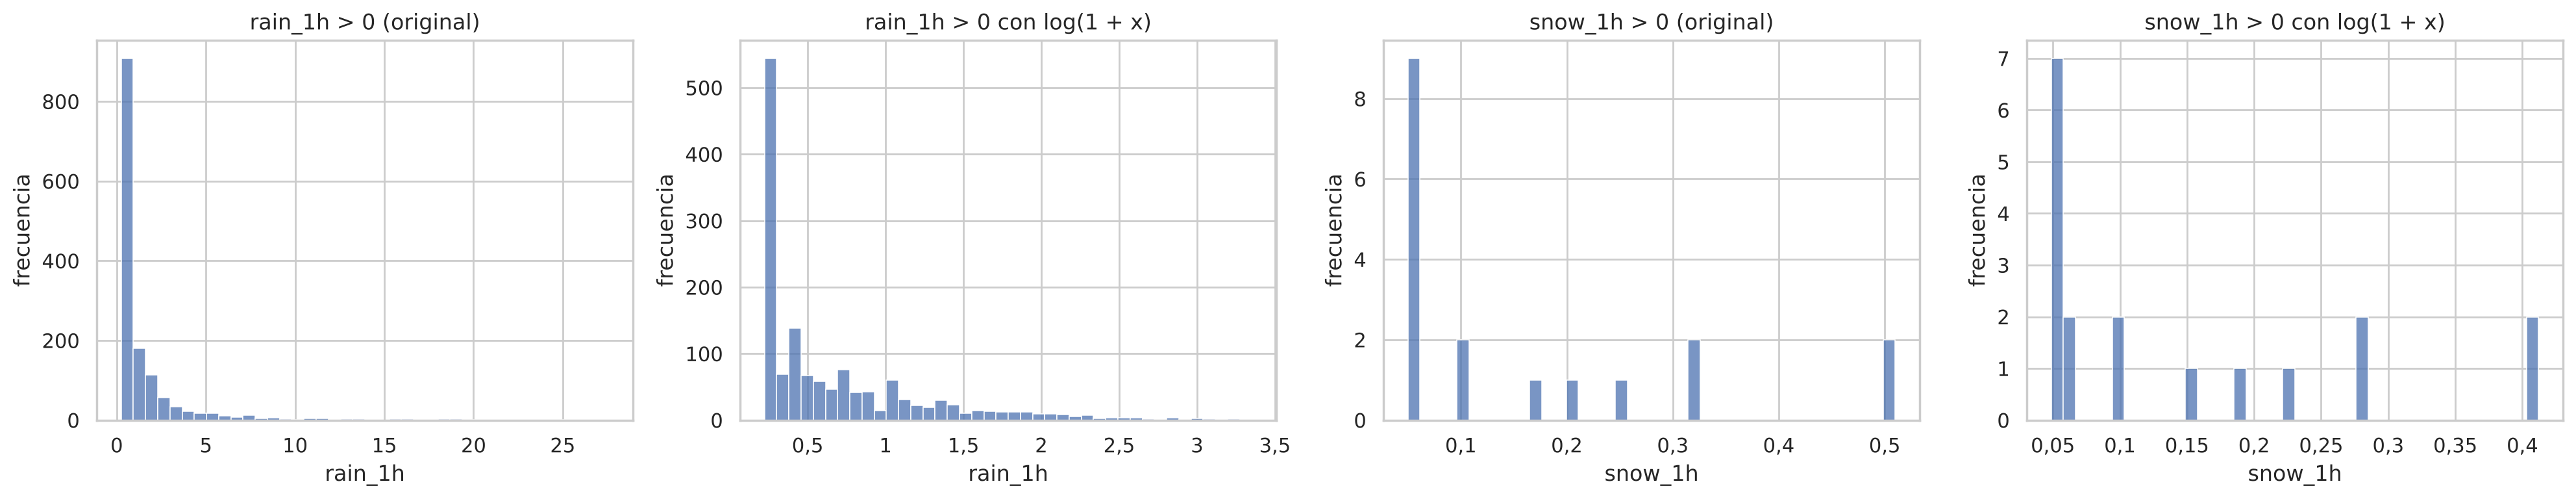

,asimetría original,asimetría con log(1 + x)
rain_1h,"19,279","8,271"
snow_1h,"71,203","67,340"


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, col in enumerate(["rain_1h", "snow_1h"]):
    positivos = train.loc[train[col] > 0, col]
    sns.histplot(positivos, bins=40, ax=axes[2 * i])
    axes[2 * i].set_title(f"{col} > 0 (original)")
    axes[2 * i].set_ylabel("frecuencia")
    sns.histplot(np.log1p(positivos), bins=40, ax=axes[2 * i + 1])
    axes[2 * i + 1].set_title(f"{col} > 0 con log(1 + x)")
    axes[2 * i + 1].set_ylabel("frecuencia")
plt.tight_layout()
ejes_es(plt.gcf())
plt.show()

asimetria_log = pd.DataFrame({
    "asimetría original": train[["rain_1h", "snow_1h"]].skew(),
    "asimetría con log(1 + x)": np.log1p(train[["rain_1h", "snow_1h"]]).skew(),
})
asimetria_log

In [20]:
bajos = train.loc[train["traffic_volume"] < 100, "date_time"].dt.date.value_counts()
print(f"Días con alguna hora de tráfico < 100: {len(bajos)}")
bajos.rename("horas con tráfico < 100").to_frame()

Días con alguna hora de tráfico < 100: 10


,horas con tráfico < 100
date_time,
2016-07-23,12
2016-07-24,5
2016-07-09,3
2016-09-01,2
2016-09-08,1
2016-08-31,1
2015-07-24,1
2015-07-25,1
2016-09-07,1


**Interpretación**

- `temp`, `clouds_all` y `traffic_volume` no tienen atípicos por IQR.
- `rain_1h` tiene cerca del 5% de horas marcadas como atípicas, que son simplemente las horas con lluvia. Con `log(1 + x)` su asimetría baja de 19 a 8.
- En `snow_1h` la transformación casi no cambia la asimetría, porque solo 18 horas de entrenamiento registran nieve: el problema no es la cola larga sino que casi todo vale 0. Se conserva la variable con la misma transformación, pero aporta poca información.
- Las horas con tráfico menor que 100 se agrupan en 10 días, casi todos entre julio y septiembre de 2016, lo que apunta a cierres de la vía y no a fallas aleatorias.

## 7. Codificación y escalamiento

Variables de entrada de los modelos:

| Grupo | Variables | Transformación |
|---|---|---|
| Precipitación | `rain_1h`, `snow_1h` | `log(1 + x)` y `StandardScaler` |
| Clima continuo | `temp`, `clouds_all` | `StandardScaler` |
| Categóricas | `weather_main`, `hora`, `dia_semana`, `mes` | One-Hot Encoding |
| Binaria | `es_festivo` | Sin cambio |

Se excluyen `weather_description` (repite la información de `weather_main` con 34 categorías, varias muy raras), `holiday` (reemplazada por `es_festivo`), `date_time` (reemplazada por sus variables derivadas) y `nivel_trafico` (se calcula a partir de `traffic_volume`, así que usarla como entrada sería fuga de datos).

Se usa `StandardScaler` para dejar todas las variables numéricas en la misma escala. No se usa `RobustScaler` porque en `rain_1h` y `snow_1h` el rango intercuartílico es 0 (casi todos sus valores son 0) y no las escalaría. Los valores altos que conservan tras la transformación logarítmica son lluvias y nevadas reales. En One-Hot Encoding, las categorías con menos de 50 registros en entrenamiento (como Squall o Smoke en `weather_main`) se agrupan en una sola; si en validación o prueba aparece una categoría de `weather_main` que no estaba en entrenamiento, se asigna a ese mismo grupo. El transformador se ajusta solo con entrenamiento y luego se aplica a validación y prueba.

In [21]:
LOG = ["rain_1h", "snow_1h"]
NUM = ["temp", "clouds_all"]
CAT = ["weather_main", "hora", "dia_semana", "mes"]
BIN = ["es_festivo"]
ENTRADAS = LOG + NUM + CAT + BIN

preprocesador = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), LOG),
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), CAT),
    ("bin", "passthrough", BIN),
])

X_train, X_val, X_test = train[ENTRADAS], val[ENTRADAS], test[ENTRADAS]
y_train_reg, y_val_reg = train["traffic_volume"], val["traffic_volume"]
y_train_clf, y_val_clf = train["nivel_trafico"].astype(str), val["nivel_trafico"].astype(str)

preprocesador.fit(X_train)
Xt_train = pd.DataFrame(preprocesador.transform(X_train), columns=preprocesador.get_feature_names_out())
n_cols_transformadas = Xt_train.shape[1]
print(f"Columnas después de transformar: {n_cols_transformadas}")
Xt_train.describe().T.loc[["log__rain_1h", "log__snow_1h", "num__temp", "num__clouds_all"], ["mean", "std"]]

Columnas después de transformar: 58


,mean,std
log__rain_1h,"0,000","1,000"
log__snow_1h,"-0,000","1,000"
num__temp,"0,000","1,000"
num__clouds_all,"-0,000","1,000"


In [22]:
print("Categorías agrupadas como infrecuentes:")
for col, cats in zip(CAT, preprocesador.named_transformers_["cat"].infrequent_categories_):
    if cats is not None:
        print(f"  {col}: {list(cats)}")

Categorías agrupadas como infrecuentes:
  weather_main: ['Smoke', 'Squall']


### Auditoría de fuga de datos (*data leakage*)

La fuga ocurre cuando información de validación o de prueba influye en el ajuste del preprocesamiento o del modelo (Kapoor y Narayanan, 2023; Kuhn y Johnson, 2019). La tabla siguiente resume en qué datos se ajusta cada paso y la celda posterior lo comprueba con verificaciones automáticas.

| Paso | Se ajusta con | Se aplica a | Riesgo de fuga |
|---|---|---|---|
| Limpieza de duplicados y valores imposibles | Reglas fijas (sin aprender de los datos) | Todo el conjunto, antes de la partición | Ninguno: no usa estadísticas ni la variable objetivo |
| Variables de calendario y `es_festivo` | Fecha y calendario de la fuente | Todo el conjunto | Ninguno: no usa la variable objetivo |
| `nivel_trafico` | Umbrales constantes (1.500 y 4.500) | Todo el conjunto | Ninguno por el cálculo; los umbrales se fijaron viendo la distribución completa (limitación declarada) |
| Partición 70/15/15 estratificada | Semilla 42 | Todo el conjunto, **antes** de imputar, codificar y escalar | Ninguno |
| Medianas de imputación | **Solo entrenamiento** | Entrenamiento, validación y prueba | Ninguno |
| `log(1 + x)` | Fórmula fija | Todos | Ninguno |
| `StandardScaler` y `OneHotEncoder` | **Solo entrenamiento** | Entrenamiento, validación y prueba | Ninguno |
| Modelos base | **Solo entrenamiento** | Validación (prueba sin usar) | Ninguno |

In [23]:
# Verificaciones automáticas de ausencia de fuga de datos
# 1) Las particiones son disjuntas y completas
assert not (set(train.index) & set(val.index)), "train y val comparten filas"
assert not (set(train.index) & set(test.index)), "train y test comparten filas"
assert not (set(val.index) & set(test.index)), "val y test comparten filas"
assert len(train) + len(val) + len(test) == len(df), "la partición no cubre todo el conjunto"

# 2) El escalador se ajustó con entrenamiento: su media coincide con la de train, no con la de todo el conjunto
escalador = preprocesador.named_transformers_["num"]
media_train = X_train[NUM].mean().to_numpy()
media_todo = pd.concat([X_train, X_val, X_test])[NUM].mean().to_numpy()
assert np.allclose(escalador.mean_, media_train), "el escalador no se ajustó solo con entrenamiento"

auditoria = pd.DataFrame({"media usada por el escalador (train)": escalador.mean_,
                          "media de todo el conjunto": media_todo,
                          "diferencia": escalador.mean_ - media_todo}, index=NUM)
print("Verificaciones superadas: particiones disjuntas y completas; escalador ajustado solo con entrenamiento.")
auditoria

Verificaciones superadas: particiones disjuntas y completas; escalador ajustado solo con entrenamiento.


,media usada por el escalador (train),media de todo el conjunto,diferencia
temp,"8,202","8,232","-0,029"
clouds_all,"44,241","44,199","0,042"


## 8. Modelo base (baseline)

Los modelos base fijan el rendimiento mínimo que los modelos de la fase siguiente deben superar. Se usan modelos lineales con la configuración por defecto de scikit-learn (en la regresión logística solo se amplía el número máximo de iteraciones para asegurar la convergencia), sin ajuste de hiperparámetros y con las mismas variables de entrada:

- **Regresión:** regresión lineal para predecir `traffic_volume`. Métricas: RMSE, MAE y R².
- **Clasificación:** regresión logística básica para predecir `nivel_trafico`. Métricas: accuracy, precisión, recall y F1-Score macro (promedio simple de las tres clases, para que cada clase pese igual).

Se evalúan en entrenamiento y validación para detectar sobreajuste. El conjunto de prueba no se usa en esta fase.

Como un modelo lineal con más de 50 columnas ya es un modelo fuerte, en la sección 8.1 se añade además una **referencia trivial** (predecir siempre la media o la clase mayoritaria), que fija el piso absoluto de rendimiento.

In [24]:
# Baseline de regresión: regresión lineal con el mismo preprocesamiento (clone → pipeline independiente)
base_reg = Pipeline([("pre", clone(preprocesador)), ("modelo", LinearRegression())])
base_reg.fit(X_train, y_train_reg)          # el preprocesador se reajusta solo con entrenamiento

def metricas_reg(y, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "MAE": mean_absolute_error(y, pred),
        "R²": r2_score(y, pred),
    }

tabla_reg = pd.DataFrame({
    "entrenamiento": metricas_reg(y_train_reg, base_reg.predict(X_train)),
    "validación": metricas_reg(y_val_reg, base_reg.predict(X_val)),
}).T
tabla_reg

,RMSE,MAE,R²
entrenamiento,"780,013","573,416","0,846"
validación,"800,055","582,801","0,838"


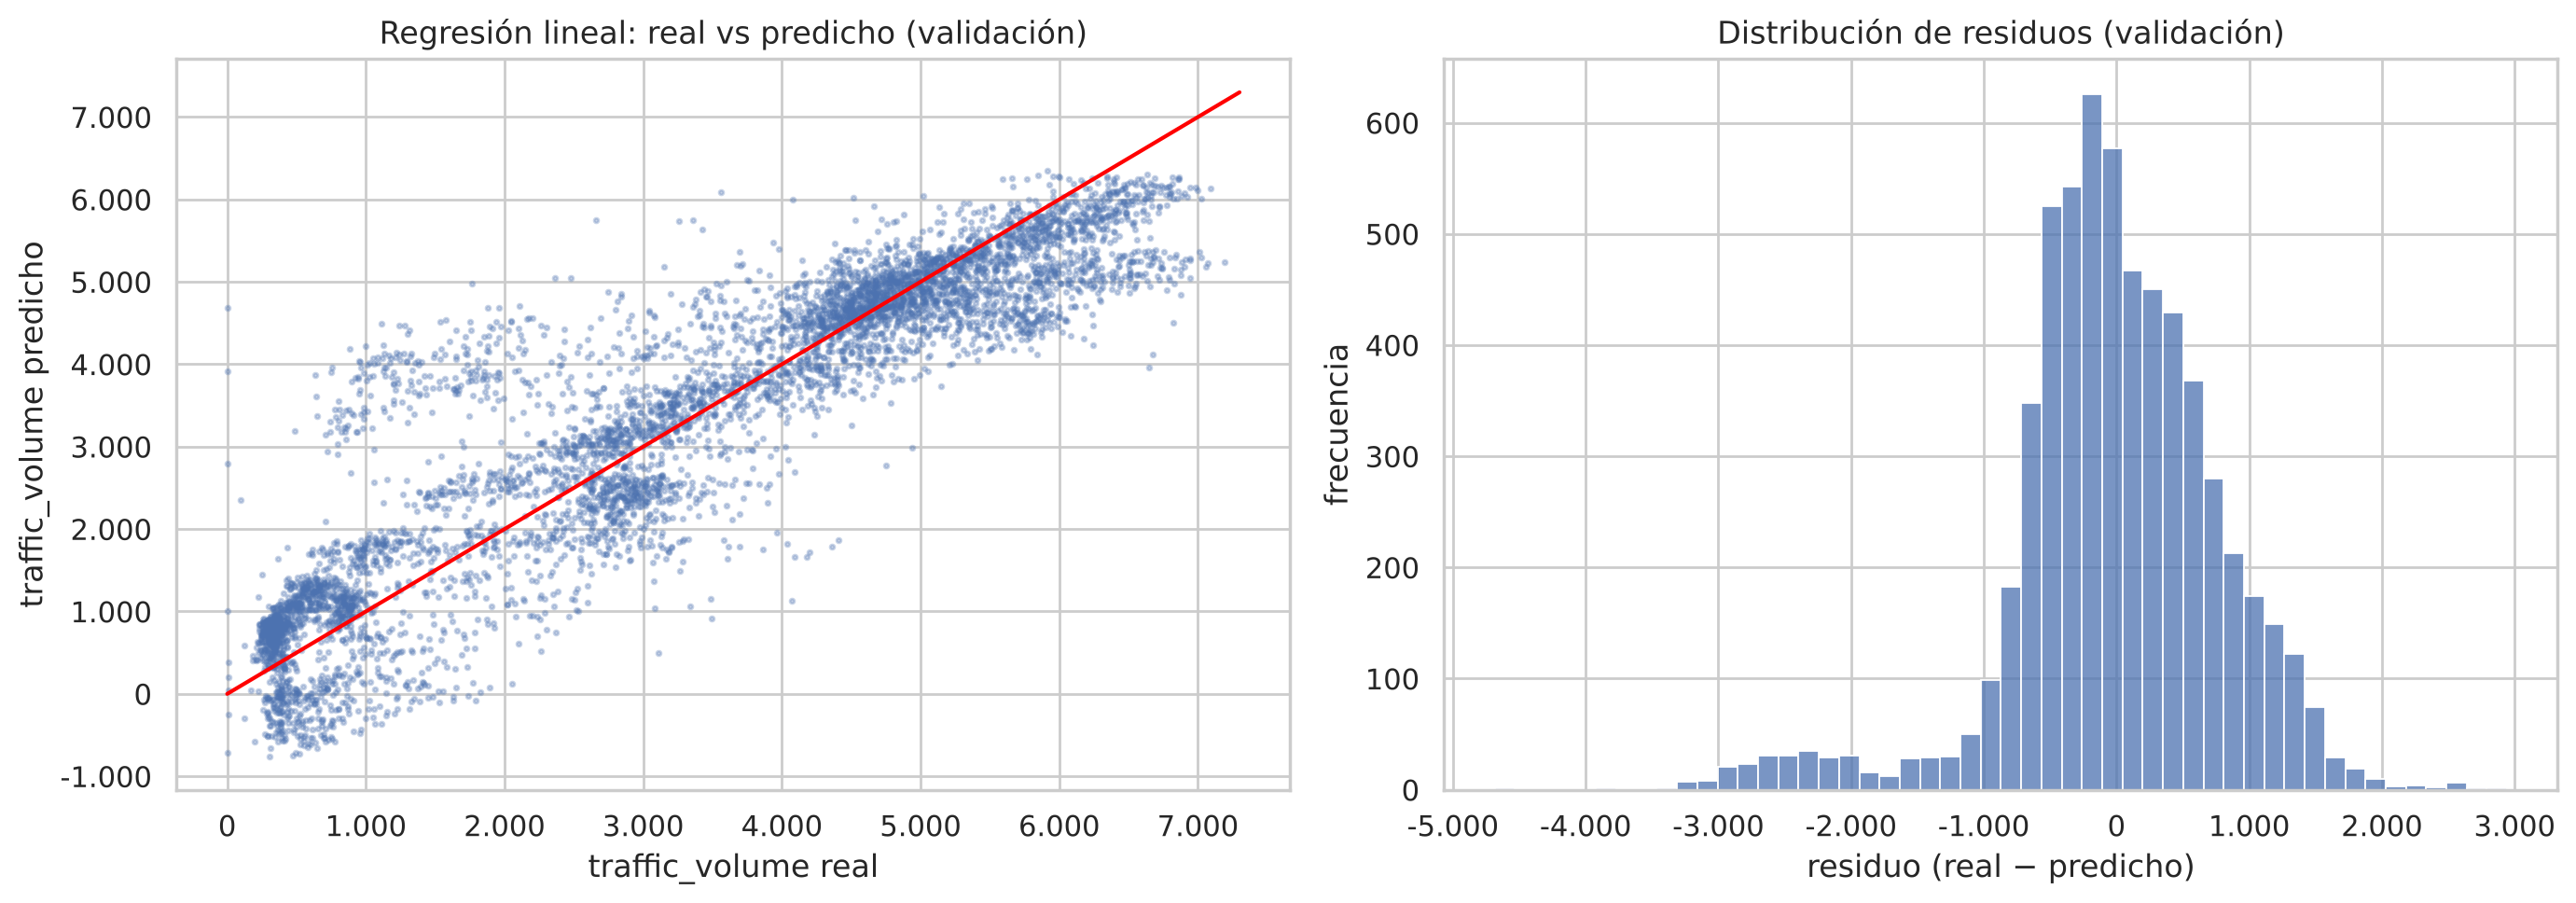

In [25]:
pred_val = base_reg.predict(X_val)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_val_reg, pred_val, s=3, alpha=0.3)
axes[0].plot([0, 7300], [0, 7300], color="red")
axes[0].set_xlabel("traffic_volume real")
axes[0].set_ylabel("traffic_volume predicho")
axes[0].set_title("Regresión lineal: real vs predicho (validación)")
sns.histplot(y_val_reg - pred_val, bins=50, ax=axes[1])
axes[1].set_xlabel("residuo (real − predicho)")
axes[1].set_ylabel("frecuencia")
axes[1].set_title("Distribución de residuos (validación)")
plt.tight_layout()
ejes_es(plt.gcf())
plt.show()

In [26]:
# Error medio (real − predicho) en validación según tipo de día y hora pico (6–8 h y 16–17 h)
residuos = pd.DataFrame({
    "tipo de día": np.where(val["dia_semana"] >= 5, "fin de semana", "laboral"),
    "hora pico": np.where(val["hora"].isin([6, 7, 8, 16, 17]), "sí", "no"),
    "residuo": y_val_reg - pred_val,
})
tabla_residuos = residuos.pivot_table(index="tipo de día", columns="hora pico", values="residuo", aggfunc="mean")
tabla_residuos

hora pico,no,sí
tipo de día,,
fin de semana,"394,471","-1.564,908"
laboral,"-157,165","586,211"


**Interpretación**

- La regresión lineal explica cerca del 84% de la variación del tráfico (R² de 0,838 en validación), con un error típico de unos 800 vehículos por hora (RMSE).
- Las métricas de entrenamiento y validación son casi iguales, así que no hay sobreajuste.
- El modelo falla en los extremos: predice valores negativos en la madrugada y se queda por debajo en las horas de más de 6.000 vehículos. Además, los residuos tienen una cola izquierda larga: en algunas horas el modelo predice bastante más tráfico del real. Esos errores se concentran en las horas pico del fin de semana: el modelo suma un efecto fijo por hora y otro por día, y predice para el sábado o el domingo a las 7:00 el aumento propio de un día laboral, que en fin de semana no ocurre.

In [27]:
# Baseline de clasificación: regresión logística básica (solo se amplía max_iter para asegurar convergencia)
base_clf = Pipeline([("pre", clone(preprocesador)), ("modelo", LogisticRegression(max_iter=1000))])
base_clf.fit(X_train, y_train_clf)

def metricas_clf(y, pred):
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precisión macro": precision_score(y, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y, pred, average="macro"),
    }

tabla_clf = pd.DataFrame({
    "entrenamiento": metricas_clf(y_train_clf, base_clf.predict(X_train)),
    "validación": metricas_clf(y_val_clf, base_clf.predict(X_val)),
}).T
tabla_clf

,Accuracy,Precisión macro,Recall macro,F1 macro
entrenamiento,"0,899","0,902","0,903","0,902"
validación,"0,888","0,891","0,892","0,891"


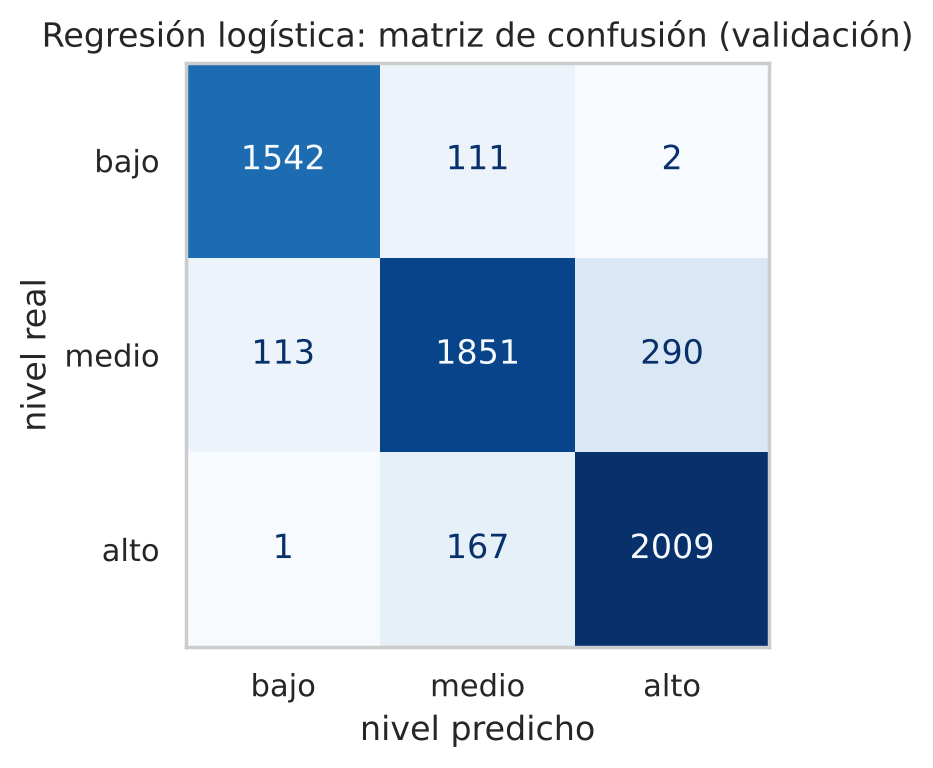

In [28]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_val_clf, base_clf.predict(X_val), labels=orden, ax=ax, colorbar=False, cmap="Blues"
)
ax.grid(False)
ax.set_title("Regresión logística: matriz de confusión (validación)")
ax.set_xlabel("nivel predicho")
ax.set_ylabel("nivel real")
plt.tight_layout()
plt.show()

In [29]:
# Métricas por clase y matriz de confusión en validación (conteos)
pred_clf_val = base_clf.predict(X_val)
informe = pd.DataFrame(classification_report(y_val_clf, pred_clf_val, labels=orden, output_dict=True, zero_division=0)).T
informe_clases = informe.loc[orden + ["macro avg"], ["precision", "recall", "f1-score", "support"]]
informe_clases.columns = ["precisión", "recall", "F1", "horas"]
informe_clases["horas"] = informe_clases["horas"].astype(int)
display(informe_clases)

cm_val = pd.DataFrame(confusion_matrix(y_val_clf, pred_clf_val, labels=orden),
                      index=[f"real {o}" for o in orden], columns=[f"pred. {o}" for o in orden])
cm_val

,precisión,recall,F1,horas
bajo,"0,931","0,932","0,931",1655
medio,"0,869","0,821","0,845",2254
alto,"0,873","0,923","0,897",2177
macro avg,"0,891","0,892","0,891",6086


,pred. bajo,pred. medio,pred. alto
real bajo,1542,111,2
real medio,113,1851,290
real alto,1,167,2009


**Interpretación**

- La regresión logística clasifica bien cerca del 89% de las horas de validación, con un F1 macro de 0,891. Entrenamiento y validación dan resultados casi iguales, así que no hay sobreajuste.
- Casi todos los errores ocurren entre clases vecinas: el nivel medio se confunde con alto o con bajo, y casi nunca se confunde bajo con alto. Es lo esperable, porque las horas cercanas a los umbrales de 1.500 y 4.500 vehículos son difíciles de separar.

In [30]:
# Lectura operativa de los errores del baseline en validación
err_abs = np.abs(y_val_reg - pred_val)
mae_rel = mean_absolute_error(y_val_reg, pred_val) / y_val_reg.mean() * 100
p500, p1000 = (err_abs < 500).mean() * 100, (err_abs < 1000).mean() * 100
pct_neg = (pred_val < 0).mean() * 100
residuo_val = y_val_reg - pred_val
res_medio_alto = residuo_val[y_val_reg > 6000].mean()      # sesgo en las horas de mayor volumen
asim_res = residuo_val.skew()                               # asimetría de los residuos

errores = cm_val.to_numpy().sum() - np.trace(cm_val.to_numpy())
extremos = int(cm_val.loc["real bajo", "pred. alto"] + cm_val.loc["real alto", "pred. bajo"])
pct_extremos = extremos / errores * 100 if errores else 0.0

operativo = {"mae_relativo_pct": mae_rel, "pct_error_menor_500": p500, "pct_error_menor_1000": p1000,
             "pct_prediccion_negativa": pct_neg, "residuo_medio_mayor_6000": res_medio_alto, "asimetria_residuos": asim_res, "errores_clasificacion": int(errores),
             "errores_bajo_alto": extremos, "pct_errores_bajo_alto": pct_extremos}

display(Markdown(
    f"**Lectura operativa.** El error absoluto medio equivale al {es(mae_rel, 1)} % del volumen medio de validación. "
    f"El {es(p500, 1)} % de las horas se predice con un error menor que 500 vehículos/h y el {es(p1000, 1)} % con uno menor que 1.000. "
    f"El {es(pct_neg, 1)} % de las predicciones son valores negativos, imposibles para un conteo de vehículos. "
    f"En las horas de más de 6.000 vehículos el residuo medio es {es(res_medio_alto, 0)} (el modelo se queda por debajo), y la asimetría de los residuos es {es(asim_res, 2)}. "
    f"En clasificación se cometen {errores} errores en validación y solo {extremos} ({es(pct_extremos, 1)} %) confunden un nivel bajo con uno alto o viceversa; "
    "el resto son errores entre niveles vecinos, que para una alerta operativa son menos costosos que un error entre extremos."))

**Lectura operativa.** El error absoluto medio equivale al 17,7 % del volumen medio de validación. El 55,9 % de las horas se predice con un error menor que 500 vehículos/h y el 84,7 % con uno menor que 1.000. El 3,7 % de las predicciones son valores negativos, imposibles para un conteo de vehículos. En las horas de más de 6.000 vehículos el residuo medio es 833 (el modelo se queda por debajo), y la asimetría de los residuos es -0,80. En clasificación se cometen 684 errores en validación y solo 3 (0,4 %) confunden un nivel bajo con uno alto o viceversa; el resto son errores entre niveles vecinos, que para una alerta operativa son menos costosos que un error entre extremos.

### 8.1 Referencia trivial (piso absoluto)

Se comparan los modelos lineales con dos modelos que no aprenden nada: predecir siempre la media de entrenamiento (regresión) o siempre la clase mayoritaria (clasificación). Cualquier modelo útil debe superarlos con claridad.

In [31]:
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor

dummy_reg = DummyRegressor(strategy="mean").fit(X_train, y_train_reg)
dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_clf)

comp_reg = pd.DataFrame({
    "Dummy (media de entrenamiento)": metricas_reg(y_val_reg, dummy_reg.predict(X_val)),
    "Regresión lineal (baseline)": metricas_reg(y_val_reg, base_reg.predict(X_val)),
}).T
comp_clf = pd.DataFrame({
    "Dummy (clase mayoritaria)": metricas_clf(y_val_clf, dummy_clf.predict(X_val)),
    "Regresión logística (baseline)": metricas_clf(y_val_clf, base_clf.predict(X_val)),
}).T
display(comp_reg)
display(comp_clf)

r_d, r_b = comp_reg.iloc[0], comp_reg.iloc[1]
c_d, c_b = comp_clf.iloc[0], comp_clf.iloc[1]
display(Markdown(
    f"**Lectura.** Prediciendo siempre la media, el R² en validación es {es(r_d['R²'])} y el RMSE {es(r_d['RMSE'], 0)} vehículos/h. "
    f"La regresión lineal baja el RMSE a {es(r_b['RMSE'], 0)} ({es((1 - r_b['RMSE'] / r_d['RMSE']) * 100, 1)} % menos) y sube el R² a {es(r_b['R²'])}. "
    f"En clasificación, predecir siempre la clase mayoritaria da una exactitud de {es(c_d['Accuracy'])} y un F1 macro de {es(c_d['F1 macro'])}, "
    f"frente a {es(c_b['Accuracy'])} y {es(c_b['F1 macro'])} de la regresión logística. "
    "El dummy es el piso absoluto; el umbral que deben superar los modelos de la Fase 3 es el baseline lineal."))

,RMSE,MAE,R²
Dummy (media de entrenamiento),"1.989,349","1.747,875","-0,000"
Regresión lineal (baseline),"800,055","582,801","0,838"


,Accuracy,Precisión macro,Recall macro,F1 macro
Dummy (clase mayoritaria),"0,370","0,123","0,333","0,180"
Regresión logística (baseline),"0,888","0,891","0,892","0,891"


**Lectura.** Prediciendo siempre la media, el R² en validación es -0,000 y el RMSE 1.989 vehículos/h. La regresión lineal baja el RMSE a 800 (59,8 % menos) y sube el R² a 0,838. En clasificación, predecir siempre la clase mayoritaria da una exactitud de 0,370 y un F1 macro de 0,180, frente a 0,888 y 0,891 de la regresión logística. El dummy es el piso absoluto; el umbral que deben superar los modelos de la Fase 3 es el baseline lineal.

### 8.2 Verificaciones de robustez

Dos decisiones del preprocesamiento admiten alternativas razonables, y se comprueba que no cambian las conclusiones. En ambas solo se usan entrenamiento y validación: el conjunto de prueba sigue sin tocarse.

1. **Imputar frente a eliminar** las filas con valores imposibles. Ambos modelos se evalúan sobre las mismas horas de validación (las que no tenían valores imposibles); la única diferencia es si el modelo se entrenó con esas filas imputadas o sin ellas.
2. **Partición aleatoria frente a temporal.** Se entrena con las horas anteriores a 2017 y se evalúa con las de 2017 en adelante (dentro de entrenamiento + validación). Si las métricas se mantienen, la partición aleatoria no está inflando el rendimiento por la cercanía entre horas vecinas.

In [32]:
# (1) Imputar vs eliminar las filas con valores imposibles
marc_tr = train.index.isin(idx_faltantes)
marc_va = val.index.isin(idx_faltantes)
print(f"Filas con valor imposible: {marc_tr.sum()} en entrenamiento, {marc_va.sum()} en validación, {test.index.isin(idx_faltantes).sum()} en prueba")

reg_elim = clone(base_reg).fit(train.loc[~marc_tr, ENTRADAS], y_train_reg[~marc_tr])
clf_elim = clone(base_clf).fit(train.loc[~marc_tr, ENTRADAS], y_train_clf[~marc_tr])

X_v, yv_r, yv_c = val.loc[~marc_va, ENTRADAS], y_val_reg[~marc_va], y_val_clf[~marc_va]

def fila(mod_reg, mod_clf):
    m = metricas_reg(yv_r, mod_reg.predict(X_v))
    return {"R²": m["R²"], "RMSE": m["RMSE"], "F1 macro": f1_score(yv_c, mod_clf.predict(X_v), average="macro")}

sens_imp = pd.DataFrame({
    "Entrenado imputando": fila(base_reg, base_clf),
    f"Entrenado eliminando las {len(idx_faltantes)} filas": fila(reg_elim, clf_elim),
}).T
display(sens_imp)
d_r2 = sens_imp.iloc[0]["R²"] - sens_imp.iloc[1]["R²"]
display(Markdown(f"**Lectura.** La diferencia de R² entre imputar y eliminar es {es(abs(d_r2), 4)} y la de F1 macro es "
                 f"{es(abs(sens_imp.iloc[0]['F1 macro'] - sens_imp.iloc[1]['F1 macro']), 4)}. "
                 "Si son del orden de milésimas, la decisión entre imputar y eliminar no afecta las conclusiones."))

Filas con valor imposible: 8 en entrenamiento, 2 en validación, 1 en prueba


,R²,RMSE,F1 macro
Entrenado imputando,"0,839","799,199","0,891"
Entrenado eliminando las 11 filas,"0,839","799,225","0,891"


**Lectura.** La diferencia de R² entre imputar y eliminar es 0,0000 y la de F1 macro es 0,0002. Si son del orden de milésimas, la decisión entre imputar y eliminar no afecta las conclusiones.

In [33]:
# (2) Validación temporal: entrenar con < 2017 y evaluar con >= 2017 (solo entrenamiento + validación)
trv = pd.concat([train, val])
CORTE = pd.Timestamp("2017-01-01")
tr_t, va_t = trv[trv["date_time"] < CORTE], trv[trv["date_time"] >= CORTE]
print(f"Entrenamiento temporal: {len(tr_t)} horas (antes de 2017) | validación temporal: {len(va_t)} horas (2017 en adelante)")

reg_t = clone(base_reg).fit(tr_t[ENTRADAS], tr_t["traffic_volume"])
clf_t = clone(base_clf).fit(tr_t[ENTRADAS], tr_t["nivel_trafico"].astype(str))
yt_r, yt_c = va_t["traffic_volume"], va_t["nivel_trafico"].astype(str)

m_alea = metricas_reg(y_val_reg, base_reg.predict(X_val))
m_temp = metricas_reg(yt_r, reg_t.predict(va_t[ENTRADAS]))
temporal = pd.DataFrame({
    "R²": [m_alea["R²"], m_temp["R²"]],
    "RMSE": [m_alea["RMSE"], m_temp["RMSE"]],
    "F1 macro": [f1_score(y_val_clf, base_clf.predict(X_val), average="macro"),
                 f1_score(yt_c, clf_t.predict(va_t[ENTRADAS]), average="macro")],
}, index=["Validación aleatoria (baseline)", "Validación temporal (≥ 2017)"])
display(temporal)

dif_r2 = temporal["R²"].iloc[0] - temporal["R²"].iloc[1]
dif_f1 = temporal["F1 macro"].iloc[0] - temporal["F1 macro"].iloc[1]
display(Markdown(
    f"**Lectura.** Al evaluar sobre un periodo posterior al de entrenamiento, el R² cambia en {es(dif_r2, 3)} puntos y el F1 macro en {es(dif_f1, 3)} "
    "(positivo = la validación aleatoria es más optimista). "
    "Una diferencia pequeña indica que la partición aleatoria no infla el rendimiento; una diferencia grande indica que debe reportarse también la métrica temporal "
    "al comparar los modelos de la Fase 3."))

Entrenamiento temporal: 21524 horas (antes de 2017) | validación temporal: 12964 horas (2017 en adelante)


,R²,RMSE,F1 macro
Validación aleatoria (baseline),"0,838","800,055","0,891"
Validación temporal (≥ 2017),"0,847","773,806","0,905"


**Lectura.** Al evaluar sobre un periodo posterior al de entrenamiento, el R² cambia en -0,009 puntos y el F1 macro en -0,014 (positivo = la validación aleatoria es más optimista). Una diferencia pequeña indica que la partición aleatoria no infla el rendimiento; una diferencia grande indica que debe reportarse también la métrica temporal al comparar los modelos de la Fase 3.

3. **Ponderación de clases.** Se entrena la regresión logística con `class_weight="balanced"` para comprobar empíricamente que, con una razón entre clases de 1,36, no hace falta tratar el desbalance (Chawla et al., 2002, proponen SMOTE para desbalances severos).
4. **Aporte de las variables derivadas.** Se entrenan los mismos modelos usando solo el clima (sin hora, día, mes ni festivo) y se comparan con el baseline completo: muestra cuánto aportan las variables de calendario creadas en la sección 3.

In [34]:
# (3) Desbalance: ¿cambia algo si se pondera por clase?
clf_bal = Pipeline([("pre", clone(preprocesador)),
                    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_train, y_train_clf)
tabla_cw = pd.DataFrame({
    "Sin ponderar (baseline)": metricas_clf(y_val_clf, base_clf.predict(X_val)),
    "class_weight='balanced'": metricas_clf(y_val_clf, clf_bal.predict(X_val)),
}).T
display(tabla_cw)

# (4) Aporte de las variables de calendario: modelos solo con clima vs. baseline completo
pre_clima = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), LOG),
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), ["weather_main"]),
])
reg_clima = Pipeline([("pre", pre_clima), ("modelo", LinearRegression())]).fit(X_train, y_train_reg)
clf_clima = Pipeline([("pre", clone(pre_clima)), ("modelo", LogisticRegression(max_iter=1000))]).fit(X_train, y_train_clf)

mr_c = metricas_reg(y_val_reg, reg_clima.predict(X_val))
mr_b = metricas_reg(y_val_reg, base_reg.predict(X_val))
tabla_abl = pd.DataFrame({
    "R²": [mr_c["R²"], mr_b["R²"]],
    "RMSE": [mr_c["RMSE"], mr_b["RMSE"]],
    "F1 macro": [f1_score(y_val_clf, clf_clima.predict(X_val), average="macro"),
                 f1_score(y_val_clf, base_clf.predict(X_val), average="macro")],
}, index=["Solo clima (sin variables de calendario)", "Baseline completo (clima + calendario)"])
display(tabla_abl)

display(Markdown(
    f"**Lectura.** Ponderar por clase cambia el F1 macro en {es(abs(tabla_cw.iloc[1]['F1 macro'] - tabla_cw.iloc[0]['F1 macro']), 4)}: no aporta, lo que respalda no aplicar SMOTE, ADASYN ni pesos. "
    f"Sin las variables de calendario el R² cae a {es(tabla_abl.iloc[0]['R²'])} y el F1 macro a {es(tabla_abl.iloc[0]['F1 macro'])}; "
    f"con ellas sube a {es(tabla_abl.iloc[1]['R²'])} y {es(tabla_abl.iloc[1]['F1 macro'])}. Las variables derivadas explican casi todo el rendimiento del baseline."))

,Accuracy,Precisión macro,Recall macro,F1 macro
Sin ponderar (baseline),"0,888","0,891","0,892","0,891"
class_weight='balanced',"0,889","0,892","0,893","0,892"


,R²,RMSE,F1 macro
Solo clima (sin variables de calendario),"0,037","1.952,583","0,380"
Baseline completo (clima + calendario),"0,838","800,055","0,891"


**Lectura.** Ponderar por clase cambia el F1 macro en 0,0010: no aporta, lo que respalda no aplicar SMOTE, ADASYN ni pesos. Sin las variables de calendario el R² cae a 0,037 y el F1 macro a 0,380; con ellas sube a 0,838 y 0,891. Las variables derivadas explican casi todo el rendimiento del baseline.

## 9. Salidas para la fase siguiente

Se guardan los conjuntos limpios e imputados, en sus unidades originales, y el preprocesador y los modelos base ya ajustados:

| Archivo | Contenido |
|---|---|
| `data/train.csv`, `data/val.csv`, `data/test.csv` | Fecha, variables de entrada y las dos variables objetivo (`traffic_volume`, `nivel_trafico`). |
| `modelos/preprocesador.joblib` | Transformador de codificación y escalamiento ajustado con entrenamiento. |
| `modelos/baseline_regresion.joblib` | Pipeline de preprocesamiento y regresión lineal. |
| `modelos/baseline_clasificacion.joblib` | Pipeline de preprocesamiento y regresión logística. |

In [35]:
# Conjuntos limpios (en unidades originales) y modelos ya ajustados, para la Fase 3
Path("../data/processed").mkdir(exist_ok=True)
Path("../models").mkdir(exist_ok=True)

COLUMNAS = ["date_time"] + ENTRADAS + ["traffic_volume", "nivel_trafico"]
for nombre, d in [("train", train), ("val", val), ("test", test)]:
    d[COLUMNAS].to_csv(f"../data/processed/{nombre}.csv", index=False)

joblib.dump(preprocesador, "../models/preprocesador.joblib")
joblib.dump(base_reg, "../models/baseline_regresion.joblib")
joblib.dump(base_clf, "../models/baseline_clasificacion.joblib")

sorted(str(p) for p in Path("../data/processed").glob("*.csv")) + sorted(str(p) for p in Path("../models").glob("*.joblib"))

['../data/processed/test.csv',
 '../data/processed/train.csv',
 '../data/processed/val.csv',
 '../models/baseline_clasificacion.joblib',
 '../models/baseline_regresion.joblib',
 '../models/preprocesador.joblib']

In [36]:
# Exporta las cifras del cuaderno a un JSON (el informe en Word usa exactamente estos valores)
def reg(d):
    """DataFrame → lista de registros (el índice pasa a ser la primera columna)."""
    return json.loads(d.reset_index().to_json(orient="records", force_ascii=False, date_format="iso"))

def num(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)

dias_sin = tabla_sin_marca.assign(fecha=tabla_sin_marca["fecha"].astype(str)) if len(tabla_sin_marca) else tabla_sin_marca

R = {
    "entorno": {"python": sys.version.split()[0], **versiones},
    "limpieza": {"n_inicial": n_inicial, "identicas": identicas, "horas_repetidas": horas_repetidas,
                 "distinto": distinto, "filas_finales": int(len(df)),
                 "desc_antes": int(antes), "desc_despues": int(despues)},
    "faltantes": reg(faltantes[["date_time", "temp", "rain_1h", "clouds_all", "weather_main", "weather_description", "traffic_volume"]]),
    "imputados": reg(imputados[["date_time", "temp", "rain_1h", "weather_description"]]),
    "mediana_lluvia": float(mediana_lluvia),
    "falta_por_mes": reg(falta_por_mes.T),
    "fisher": reg(fisher_tabla),
    "cobertura_anual": reg(cobertura_anual),
    "bloques_resumen": reg(resumen_bloques),
    "bloques_top": reg(bloques_top),
    "bloques_una_hora": n_bloques_1h,
    "huecos_cortos": reg(huecos_cortos),
    "festivos": {"horas_holiday": int((df["holiday"] != "None").sum()), "horas_es_festivo": int(df["es_festivo"].sum()),
                 "promedio": reg(festivo_prom), "federales_con_datos": len(con_datos),
                 "federales_sin_marca": reg(dias_sin), "horas_sin_marca": horas_sin_marca},
    "particion": reg(particion),
    "razon_clases": float(razon_clases),
    "atipicos": reg(tabla_atipicos),
    "asimetria_log": reg(asimetria_log),
    "dias_trafico_bajo": int(len(bajos)),
    "bajos_top": reg(bajos.head(5).rename("horas").to_frame()),
    "n_columnas_transformadas": int(n_cols_transformadas),
    "infrecuentes": {c: list(cats) for c, cats in zip(CAT, preprocesador.named_transformers_["cat"].infrequent_categories_) if cats is not None},
    "auditoria_escalador": reg(auditoria),
    "baseline": {"reg": reg(tabla_reg), "clf": reg(tabla_clf), "dummy_reg": reg(comp_reg), "dummy_clf": reg(comp_clf),
                 "residuos": reg(tabla_residuos), "cm": reg(cm_val), "por_clase": reg(informe_clases)},
    "operativo": operativo,
    "robustez": {"imputar_vs_eliminar": reg(sens_imp), "temporal": reg(temporal),
                 "class_weight": reg(tabla_cw), "ablacion": reg(tabla_abl),
                 "n_temporal_train": int(len(tr_t)), "n_temporal_val": int(len(va_t))},
}
Path("../models/resultados_fase2.json").write_text(json.dumps(R, default=num, ensure_ascii=False, indent=1), encoding="utf-8")
print("Cifras exportadas a ../models/resultados_fase2.json")

Cifras exportadas a ../models/resultados_fase2.json


## 10. Conclusiones

Los datos quedaron listos para modelar: cada hora aparece una sola vez, los errores de medición se corrigieron según el mecanismo que los produjo y las categorías quedaron uniformes. Las variables de calendario derivadas de la fecha recogen el patrón diario y semanal que muestra el tráfico de la I-94, junto con el efecto de los festivos. La partición estratificada y el ajuste de la imputación, la codificación y el escalamiento solo con entrenamiento evitan la fuga de datos, y el conjunto de prueba queda sin tocar para la evaluación final. Además, la sección 8 incluye una referencia trivial (dummy) y cuatro verificaciones de robustez: imputar frente a eliminar, validación temporal, ponderación de clases y aporte de las variables derivadas; la sección 7 incluye una auditoría automática de fuga de datos.

Los modelos base ya alcanzan un rendimiento alto y sin sobreajuste, de modo que el umbral que deben superar los modelos de la fase siguiente es exigente. Sus errores muestran dónde está el margen de mejora: en las horas extremas y en los cambios de patrón entre días laborales y fines de semana, que un modelo lineal no puede representar. Modelos que capten interacciones entre la hora, el día y el clima deberían reducir esos errores.

## 11. Lista de verificación frente a la guía (Entregable 2)

| Requisito de la guía | Dónde se cumple |
|---|---|
| Valores faltantes e imposibles tratados con justificación y análisis del mecanismo (MCAR, MAR, MNAR) | Secciones 2 y 5 (incluye la prueba de Fisher) |
| Eliminación frente a imputación justificada | Sección 5 y verificación 8.2 (1) |
| Atípicos tratados con razonamiento (transformación logarítmica) | Sección 6 |
| Al menos 2 variables derivadas con respaldo del dominio | Sección 3 (cuatro variables) y verificación 8.2 (4) |
| Codificación y escalamiento sin fuga de datos | Sección 7 y auditoría de fuga |
| Partición Entrenamiento/Validación/Prueba (70/15/15) estratificada | Sección 4 y verificación 8.2 (2) |
| Desbalance tratado o descartado con evidencia | Sección 4 y verificación 8.2 (3) |
| Modelo base establecido (referencia trivial y modelos lineales) | Sección 8 (8.1 y modelos base) |
| Código reproducible con `requirements.txt` | Celda de versiones y estructura del repositorio |

## 12. Referencias (APA, 7.ª edición)

Chawla, N. V., Bowyer, K. W., Hall, L. O., y Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953

Hogue, J. (2019). *Metro Interstate Traffic Volume* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5X60B

Kapoor, S., y Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns, 4*(9), 100804. https://doi.org/10.1016/j.patter.2023.100804

Kuhn, M., y Johnson, K. (2019). *Feature engineering and selection: A practical approach for predictive models*. CRC Press.

Little, R. J. A., y Rubin, D. B. (2019). *Statistical analysis with missing data* (3.ª ed.). John Wiley & Sons. https://doi.org/10.1002/9781119482260

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581